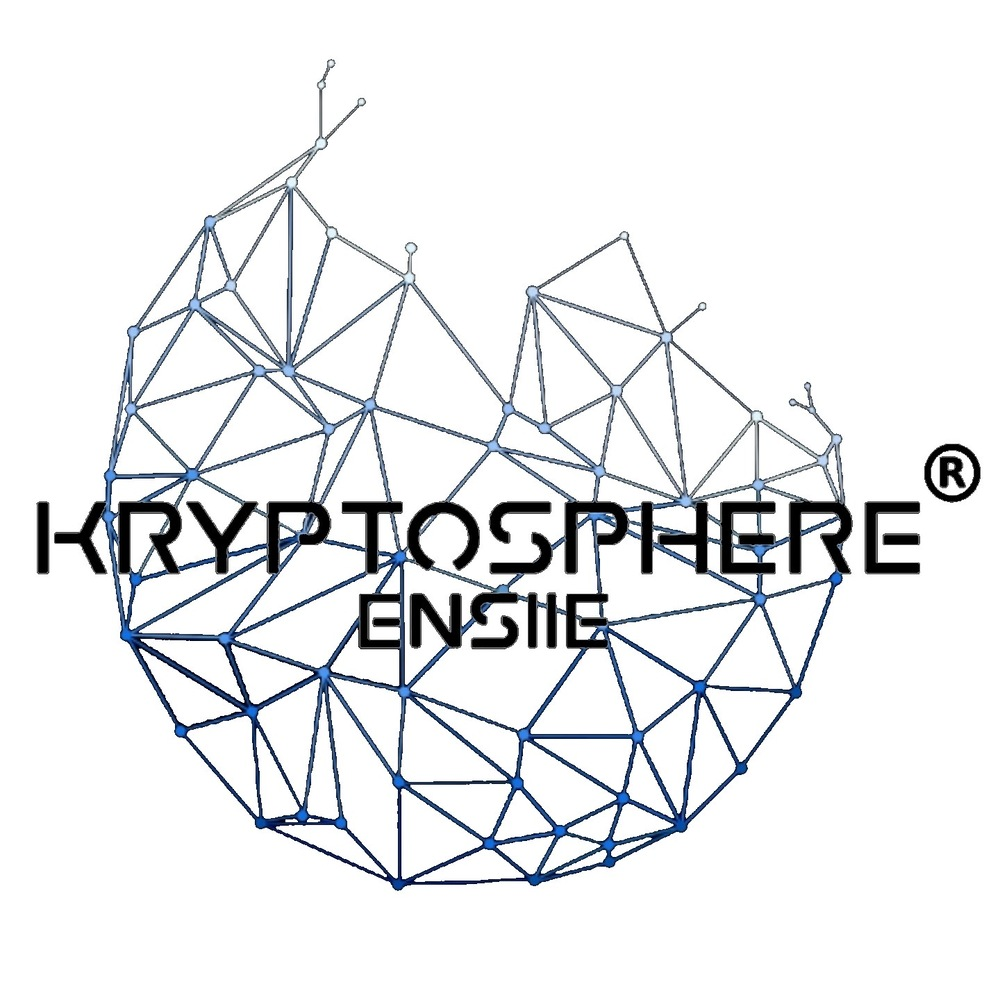

🚀 L'antenne KRYPTOSHERE à l'ensIIE

KRYPTOSHERE est une association étudiante dédiée à la promotion et à la compréhension des technologies émergentes telles que la blockchain, l’intelligence artificielle et la finance numérique.

À travers des formations, conférences, meet-ups et hackathons, nous offrons à nos membres l’opportunité de développer des compétences concrètes, d’approfondir leurs connaissances et de participer activement à l’innovation dans ces domaines en pleine expansion.

Rejoindre KS, c’est faire le choix d’une expérience enrichissante, de montée en compétences rapide, et de contribution au rayonnement de l’école à travers des projets à fort impact.

In [ ]:
# Author: Mouhamed Nourou Dine Cisse
# importation des packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# **Preprocessing**

Le preprocessing est une étape importante, si ce n’est la plus importante, en machine learning.  
Car un modèle a beau être robuste, si les données ne sont pas bien traitées, ses performances resteront faibles.  

On va voir **quatre étapes clés** du preprocessing :

---

## **1- L’analyse des valeurs aberrantes**

Il s’agit de détecter les *outliers*, autrement dit les anomalies dans le dataset.  
Elles peuvent être dues à des erreurs de saisie ou à des cas extrêmes ne reflétant pas la réalité générale.  
Ces valeurs peuvent fausser les statistiques et tromper le modèle.  
On les repère souvent à l’aide de boxplots, scatter plots ou de mesures comme le *z-score* ou l’IQR.

---

## **2- Le traitement des valeurs manquantes**

Un dataset n’est pas toujours complet.  
Certaines cellules peuvent être vides (*NaN*) à cause d’erreurs lors de la collecte ou simplement d’une absence d’information.  
Avant d’entraîner un modèle, il faut décider quoi en faire :  
- Supprimer les lignes ou colonnes concernées  
- Remplacer les valeurs manquantes par une moyenne, une médiane ou une valeur la plus fréquente (*imputation*)  
- Ou utiliser des méthodes plus avancées selon le contexte  

---

## **3- L’encodage**

On a souvent des variables non numériques.  
Comme les modèles de machine learning reposent sur des calculs mathématiques, il faut transformer ces variables en nombres.  
Les principales techniques d’encodage sont :  
- **One-Hot Encoding** : crée une colonne binaire pour chaque catégorie  
- **Label Encoding** : attribue un entier à chaque catégorie  
- **Embeddings** : pour représenter des catégories nombreuses dans un espace vectoriel  

---

## **4- La standardisation**

Dans un dataset, les variables n’ont souvent pas la même unité ni la même échelle.  
Il peut exister un grand écart entre les valeurs de certaines variables.  
La standardisation permet de ramener toutes les valeurs sur une échelle comparable, par exemple dans l’intervalle [-1, 1] ou centrée autour de 0.  
Cela crée une équité entre les variables aux yeux du modèle et améliore la convergence des algorithmes d’apprentissage.


## **1- L’analyse des valeurs aberrantes**

In [ ]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

# Charger le dataset en dataframe
california = fetch_california_housing(as_frame=True)
df = california.data
# Ajouter la cible
cible = "MedHouseVal"
df[cible] = california.target  # la valeur médiane des maisons
df.head()


In [ ]:
# Desciption de la base de données
df.describe()

# Détéction graphique des outliers

In [ ]:
import seaborn as sns
# Visualiser les outliers en utilisant un boxplot avec Seaborn
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x=cible)
plt.xlabel('Prix médiane des maisons')
plt.title("Boxplot des prix médiane des maisons en Californie")
plt.show()

In [ ]:
# Distribution de la cible
sns.histplot(df[cible], bins=20, color="green", alpha=0.3)
plt.grid()

### IQR (Interquartile Range)

L'**IQR** est une mesure de dispersion qui indique l'étendue des valeurs centrales d'une variable.  

- **Q1** : 1er quartile (25% des données sont en dessous)  
- **Q3** : 3e quartile (75% des données sont en dessous)  
- **IQR = Q3 − Q1**  

**Détection des outliers** :  
- Valeurs < Q1 − 1.5 × IQR  
- Valeurs > Q3 + 1.5 × IQR  

In [ ]:

# Identification des données aberrantes - IQR
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return data[(data[column] < lower_bound) | (data[column] > upper_bound)], lower_bound, upper_bound

outliers, lower_bound, upper_bound = detect_outliers_iqr(df,cible)
outliers

In [ ]:
# Supprimer les outliers que si on est sure que c'est des valeurs pas réalistes
data_no_outliers = df[(df[cible] >= lower_bound) & (df[cible] <= upper_bound)]



## **2- Le traitement des valeurs manquantes**

In [ ]:
# Chargement des donnees
from seaborn import load_dataset
df_titanic = load_dataset(name="titanic")
df_titanic.head()

In [ ]:
# drop des colonnes redondantes
# Enlever la colonne who, alive, class
to_drop = ['who', 'alive', 'class']
# votre code

In [ ]:
# informations générales du dataset
df_titanic.info()

In [ ]:
# Tableau du pourcentage de valeurs manquantes par colonne
df_titanic.isna().sum() / df_titanic.shape[0]

## Imputation par la médiane, la moyenne et le mode
Il s'agit de remplacer les valeurs manquantes dans une colonne par la moyenne (variables continues et symétriques) ou la médiane (distribution assymétrique) de la colonne ou la mode (valeur le plus fréquente) s'il s'agit d'une variable catégorielle.

In [ ]:
# Distribution de la variable age
sns.histplot(df_titanic['age'], bins=20, alpha=0.3, color="red")
plt.grid()

In [ ]:
# imputation par la moyenne de la variable age
from sklearn.impute import SimpleImputer
mean_imputer = SimpleImputer(strategy="mean")
df_titanic[['age']] = mean_imputer.fit_transform(df_titanic[['age']])
df_titanic.isna().sum() / df_titanic.shape[0]


In [ ]:
# imputation par la mode des variables embarked, embark_town et deck
mode_imputer = SimpleImputer(strategy="most_frequent")

# Pour embarked
df_titanic[['embarked']] = mode_imputer.fit_transform(df_titanic[['embarked']])

# Repeter la meme operation pour embark_town et deck

# Pour embark_town
# votre code ici

# Pour deck
# votre code ici

# affichager les Nan
# votre code ici

## **3- L’encodage**

In [ ]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder
# affichage des types de données
df_titanic.dtypes

### **1. Label Encoding**
- Chaque catégorie devient un entier unique.  
- **Avantage** : simple, rapide, adapté aux variables ordonnées.  
- **À éviter** : pour les variables non ordonnées, crée un ordre implicite.  


In [ ]:
# encodage de sex, alone et adult_male
to_le_col = ['sex', 'alone', 'adult_male', 'embarked', 'deck', 'embark_town']

le = LabelEncoder()
for col in to_le_col:
  df_titanic[col] = le.fit_transform(df_titanic[col])
df_titanic.head()

### **2. One-Hot Encoding**
- Une colonne binaire par catégorie.  
- **Avantage** : pas d’ordre, compatible avec la plupart des modèles.  
- **Limite** : beaucoup de colonnes si nombreuses catégories.  

In [ ]:
# Selection de variable avec la matrice de correlation
import seaborn as sns
corr = df_titanic.corr()
sns.heatmap(corr, annot=True)


## **4- La standardisation**

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Exemple : features numériques du Titanic
numeric_features = ['age', 'fare', 'sibsp', 'parch']

# 1. Créer le scaler
scaler = StandardScaler()

# 2. Appliquer la standardisation
# fit_transform : calcule la moyenne et l'écart-type sur les données et les transforme
df_titanic[numeric_features] = scaler.fit_transform(df_titanic[numeric_features])

# 3. Afficher le résultat
df_titanic.head()


# Modélisation

La modélisation est l’étape où l’on choisit un algorithme pour apprendre la relation entre les **features** et la **target**.  

### **1. Choix du modèle**
- Ici : **Random Forest Classifier**  
- Un ensemble d’arbres de décision combinés pour améliorer la précision et réduire le surapprentissage.  
- Avantages :
  - Gère les variables numériques et encodées  
  - Robuste aux valeurs aberrantes et au bruit  
  - Permet d’estimer l’importance des features  

### **2. Séparation des données**
- Les données sont divisées en **train (80%)** et **test (20%)**.  
- Le modèle apprend sur le train et est évalué sur le test, jamais vu par le modèle.  

### **3. Évaluation du modèle**
- **Accuracy** : proportion de prédictions correctes  
$$
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
$$  

- **Précision (Precision)** : vrai positif parmi les prédits positifs  
$$
Precision = \frac{TP}{TP + FP}
$$  

- **Rappel (Recall / Sensitivity)** : vrai positif parmi les vrais positifs  
$$
Recall = \frac{TP}{TP + FN}
$$  

- **F1-score** : moyenne harmonique de précision et rappel  
$$
F1 = 2 \cdot \frac{Precision \times Recall}{Precision + Recall}
$$  

### **4. Possibilités d’autres modèles**
- **Logistic Regression** : simple et interprétable  
- **Support Vector Machine (SVM)** : efficace pour des frontières complexes  
- **K-Nearest Neighbors (KNN)** : basé sur la proximité entre points  
- **Gradient Boosting / XGBoost** : très performant pour des datasets structurés


## Regression
## Regression
### **3. Évaluation du modèle**
Pour les problèmes de régression, on utilise des métriques adaptées aux variables continues :  

- **MSE (Mean Squared Error)** : moyenne des carrés des erreurs  
$$
MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$  

- **RMSE (Root Mean Squared Error)** : racine carrée du MSE, même unité que la target  
$$
RMSE = \sqrt{MSE}
$$  

- **MAE (Mean Absolute Error)** : moyenne des erreurs absolues  
$$
MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|
$$  

- **R² Score** : proportion de la variance expliquée par le modèle  
$$
R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}
$$  

In [ ]:
from sklearn.model_selection import train_test_split # Pour séparer les donnees d'entrainement et de test
from sklearn.ensemble import RandomForestClassifier # modele a utiliser
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Définition des features et target

y = df_titanic['survived']

# Features : toutes les colonnes numériques et encodées
X = df_titanic.drop(columns=['survived'])

# Séparation train / test

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Modélisation avec Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Prédiction sur le jeu test
y_pred = rf.predict(X_test)

# Évaluation du modèle

# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Rapport détaillé
cr = classification_report(y_test, y_pred)
print("Classification Report:\n", cr)

# Importance des features
importances = pd.Series(rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)
print("Feature importances:\n", importances)


In [ ]:
# Cross-validation avec 5 folds
from sklearn.model_selection import cross_val_score
scores = cross_val_score(rf, X, y, cv=5, scoring='f1')

# Affichage des scores
print("f1-score pour chaque fold :", scores)
print("f1-score moyen :", scores.mean())

# Tracer la courbe
plt.figure(figsize=(6,4))
plt.plot(range(1, 6), scores, marker='o', linestyle='--', color='b')
plt.title("f1-score par fold - Cross Validation")
plt.xlabel("Fold")
plt.ylabel("f1-score")
plt.ylim(0,1)
plt.grid(True)
plt.show()

Exercice: Continuer le preprocessiong sur le dataset california housing (df) et compléter le modèle RandomForest suivant. Tester d'autres modèles et comparer les résultats.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
import pandas as pd

# 1. Définir la target et les features
# TODO : Remplacer ___ par la colonne cible
y = df['___']
X = df.drop(columns=['___'])

# 2. Séparer les données en train et test
# TODO : compléter test_size et random_state si nécessaire
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=___, random_state=___
)

# 3. Créer et entraîner le modèle Random Forest Regressor
# TODO : ajuster le nombre d'arbres si voulu
rf_reg = RandomForestRegressor(n_estimators=___, random_state=___)
rf_reg.fit(___, ___)

# 4. Faire des prédictions
y_pred = ___

# 5. Calculer les métriques
mse = mean_squared_error(___, ___)
rmse = mean_squared_error(___, ___, squared=False)
mae = mean_absolute_error(___, ___)
r2 = r2_score(___, ___)

print(f"MSE: {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"MAE: {mae:.3f}")
print(f"R2 Score: {r2:.3f}")

# 6. Importance des features
# TODO : créer une série pandas triée par importance
importances = pd.Series(rf_reg.feature_importances_, index=___).sort_values(ascending=False)
print("Feature importances:\n", importances)
